# Dummy S2 timing maps: electroluminescence and optical propagation

An S2 photon reaches a PMT some time after its electron was extracted from the liquid. The ember plugin `S2PhotonPropagation` adds up four delays for every photon:

| Delay | Model in ember | Input |
|---|---|---|
| **Electroluminescence**: the electron crosses the gas gap and emits light all along its way | inverse CDF of the emission time | map `s2_luminescence_timing_dummy.json` (**this notebook**) |
| **Excimer decay**: the excited xenon dimers live a few ns (singlet) or ~100 ns (triplet) | exponential decays | `singlet_fraction_gas`, `singlet_lifetime_gas`, `triplet_lifetime_gas` in `detector.yaml` |
| **Optical propagation**: the photon travels to a PMT, possibly with reflections | inverse CDF per PMT array | map `s2_optical_propagation_dummy.json` (**this notebook**) |
| **PMT transit time** | normal distribution | `pmt_transit_time_mean`, `pmt_transit_time_spread` in `detector.yaml` |

Both maps built here are **dummy maps** from simple models. For a real detector they should be replaced by maps from detailed simulations: the electroluminescence timing for example from a Garfield++ simulation of the electron drift in the field of the real anode, the optical delays from a full optical simulation (e.g. Geant4). The formats stay the same, so a new file can replace a dummy map without code changes.

### Format of the maps

Both maps are **inverse cumulative distribution functions** (inverse CDF) of a delay $t$:

$$t = F^{-1}(u), \qquad u \in [0, 1].$$

For a uniform random number $u$, the map returns the delay below which a fraction $u$ of the photons arrive. Drawing $u$ uniformly therefore gives delays with the right distribution. The delays must not decrease with $u$. The coordinate system has one axis `u` with evenly spaced points, and values in between are interpolated linearly.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import strax

import ember
from ember.electron_transport import (
    anode_field_profile,
    build_luminescence_timing_map,
    electroluminescence_duration,
    electroluminescence_yield_per_length,
    xenon_number_density,
)
from ember.maps import load_map, save_map_data
from ember.optical_toy_mc import (
    OUTCOME_BOTTOM,
    OUTCOME_TOP,
    TpcOptics,
    build_s2_timing_map,
    simulate_s2_photons,
)
from ember.url_protocols import DUMMY_MAP_DIRECTORY

## Part 1: Electroluminescence timing

After its extraction, the electron is accelerated by the strong field in the gas between the liquid surface and the anode. On its way it excites xenon atoms, which emit the S2 light. The light is therefore emitted over the whole time the electron needs to reach the anode. How the light is spread over this time depends on the field along the path of the electron:

* the **drift velocity** of the electron in the gas, which we take from NEST,
* the **light emitted per cm of path**, which grows linearly with the reduced field $E/N$ ($N$: number of xenon atoms per cm³). We use the fit of Monteiro et al., JINST 2 (2007) P05001, eq. 8:

$$\frac{Y}{N} = 0.140\,\frac{E}{N} - 0.474 \quad \left[10^{-17}\,\mathrm{photons\,cm^2\,electron^{-1}\,atom^{-1}}\right], \qquad E/N \text{ in Td} = 10^{-17}\,\mathrm{V\,cm^2}.$$

Below $E/N = 3.39$ Td no light is emitted.

The field in the gas far from the anode follows from the field in the liquid: at the liquid surface the electric displacement is continuous, so $E_\mathrm{gas} = \varepsilon_\mathrm{LXe} \cdot E_\mathrm{liquid}$ with the relative permittivity $\varepsilon_\mathrm{LXe} = 1.96$. Close to the anode the field depends on the type of anode:

* **Mesh (default)**: we treat the gate-anode region as ideal parallel plates. The field is uniform up to the anode, so the electron moves with constant velocity and emits the same amount of light per ns. The emission time is **uniform** between 0 and the crossing time.
* **Wire grid**: each wire collects the field lines of one wire pitch $s$. Close to a wire, the field grows like the field of a charged line, $E(r) = E_\mathrm{gas} \cdot s / (2\pi r)$, for distances $r < s / 2\pi$ from the wire axis. The electron gets faster and emits much more light at the end of its path. An example follows below.

Time 0 is the moment the electron leaves the liquid. Not included: diffusion of the electron in the gas, different paths of the electrons around the wires, and a gas gap that changes with $(x, y)$. All of them smear the shape further.

In [2]:
z_liquid_level = strax.URLConfig.evaluate_dry("detector://z_liquid_level")
z_anode = strax.URLConfig.evaluate_dry("detector://z_anode")
extraction_field_liquid = strax.URLConfig.evaluate_dry("detector://extraction_field_liquid")
lxe_dielectric_constant = strax.URLConfig.evaluate_dry("detector://lxe_dielectric_constant")
temperature = strax.URLConfig.evaluate_dry("detector://liquid_temperature")
pressure = strax.URLConfig.evaluate_dry("detector://gas_pressure")
xenon_density_gas = strax.URLConfig.evaluate_dry("detector://xenon_density_gas")

gas_gap = z_anode - z_liquid_level
field_gas = lxe_dielectric_constant * extraction_field_liquid
reduced_field = field_gas / xenon_number_density(xenon_density_gas) / 1e-17
duration = electroluminescence_duration(gas_gap, field_gas, temperature, pressure, xenon_density_gas)

print(f"Gas gap: {gas_gap * 10:.2f} mm")
print(f"Field in the liquid: {extraction_field_liquid:.0f} V/cm, in the gas: {field_gas:.0f} V/cm ({reduced_field:.1f} Td)")
print(f"Drift velocity in the gas (NEST): {gas_gap / duration * 1e4:.2f} mm/us")
print(f"Crossing time of the gas gap with a mesh anode: {duration:.0f} ns")

Gas gap: 2.99 mm
Field in the liquid: 3571 V/cm, in the gas: 7000 V/cm (8.6 Td)
Drift velocity in the gas (NEST): 4.80 mm/us
Crossing time of the gas gap with a mesh anode: 623 ns


Build the map for a **mesh anode** and save it. For a mesh the inverse CDF is a straight line from $(u = 0, t = 0)$ to $(u = 1, t = T)$:

In [3]:
luminescence_map = build_luminescence_timing_map(
    gas_gap, field_gas, temperature, pressure, xenon_density_gas, anode_wire_pitch=None, anode_wire_radius=None
)
luminescence_map["name"] = "Dummy S2 electroluminescence timing map"
luminescence_map["description"] = (
    f"Electroluminescence emission time [ns] after the extraction as inverse CDF in u. Mesh anode (uniform "
    f"field): gas gap {gas_gap:.4f} cm, field {field_gas:.0f} V/cm, NEST drift velocity in the gas, light "
    f"yield of Monteiro et al. (2007), crossing time {duration:.1f} ns."
)
luminescence_map["timestamp"] = time.time()

luminescence_file = DUMMY_MAP_DIRECTORY / "s2_luminescence_timing_dummy.json"
save_map_data(luminescence_map, luminescence_file)
print("Saved", luminescence_file)

Saved /mnt/d/XLZD/mymodules/ember/ember/dummy_maps/s2_luminescence_timing_dummy.json


### Example: wire anode

For comparison we build the map for a grid of anode wires similar to XENONnT, with the values of fuse's public configuration: wire radius 0.108 mm and a distance of 0.89 mm in which the field of the wire dominates, i.e. a wire pitch of $2\pi \cdot 0.89$ mm $= 5.6$ mm. This map is **not saved**. To use a wire anode in the simulation, pass these parameters when building `luminescence_map` above.

The left plot shows the field along the path of the electron, the middle plot the light emitted per mm of path and the right plot the distribution of the emission time. With wires, the electron emits only a little light far from the anode and most of its light in the last ~0.1 mm in front of the wire:

mesh  : emission ends after 623 ns, median 310 ns
wires : emission ends after 527 ns, median 473 ns


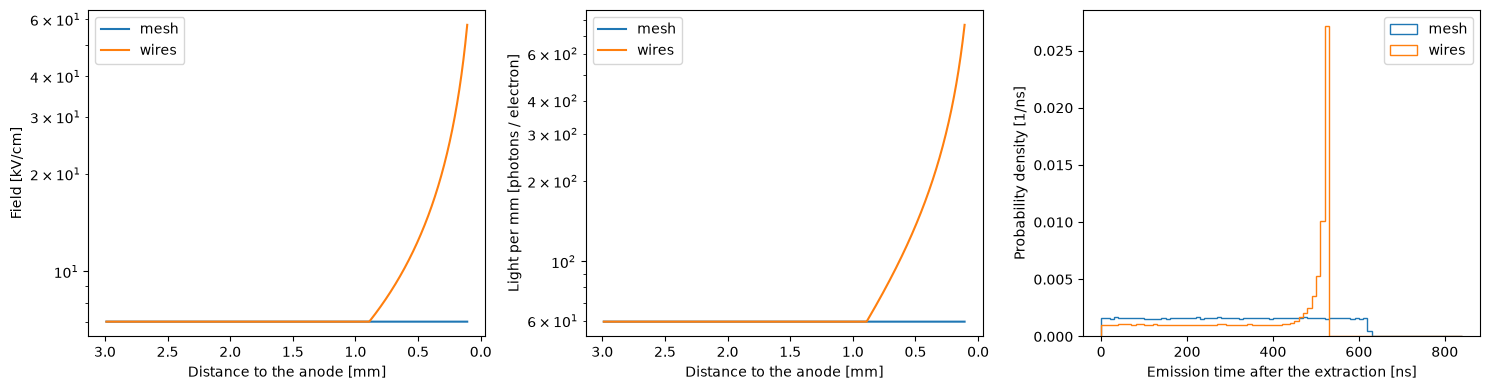

In [4]:
anode_wire_radius = 0.0108  # cm
anode_wire_pitch = 2 * np.pi * 0.089  # cm

wire_luminescence_map = build_luminescence_timing_map(
    gas_gap,
    field_gas,
    temperature,
    pressure,
    xenon_density_gas,
    anode_wire_pitch=anode_wire_pitch,
    anode_wire_radius=anode_wire_radius,
)

distance_to_anode = np.linspace(gas_gap, anode_wire_radius, 2000)
number_density = xenon_number_density(xenon_density_gas)
rng = np.random.default_rng(0)
u_random = rng.random(200_000)
u_grid = np.linspace(0, 1, 1001)

figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for label, pitch, timing_map in [
    ("mesh", None, luminescence_map),
    ("wires", anode_wire_pitch, wire_luminescence_map),
]:
    field = anode_field_profile(distance_to_anode, field_gas, anode_wire_pitch=pitch)
    light_per_mm = electroluminescence_yield_per_length(field, number_density) / 10
    emission_times = np.interp(u_random, u_grid, timing_map["map"])
    axes[0].plot(distance_to_anode * 10, field / 1e3, label=label)
    axes[1].plot(distance_to_anode * 10, light_per_mm, label=label)
    axes[2].hist(emission_times, bins=np.arange(0, 850, 10), histtype="step", density=True, label=label)
    print(f"{label:6s}: emission ends after {timing_map['map'][-1]:.0f} ns, median {np.median(emission_times):.0f} ns")

axes[0].set_ylabel("Field [kV/cm]")
axes[0].set_yscale("log")
axes[1].set_ylabel("Light per mm [photons / electron]")
axes[1].set_yscale("log")
for axis in axes[:2]:
    axis.set_xlabel("Distance to the anode [mm]")
    axis.invert_xaxis()
axes[2].set_xlabel("Emission time after the extraction [ns]")
axes[2].set_ylabel("Probability density [1/ns]")
for axis in axes:
    axis.legend()
plt.tight_layout()
plt.show()

## Part 2: Optical propagation timing

The S2 light is emitted in the gas, just below the top PMTs. Photons going up reach the top array after a few cm. Photons going down cross the liquid surface, travel through the whole liquid xenon to the bottom array and may be scattered or reflected on the PTFE walls on their way.

We use ember's optical toy Monte Carlo (`ember/optical_toy_mc.py`), the same one as for the S1 timing map. See `dummy_s1_timing_maps.ipynb` for the processes it includes and the optical parameters in `detector.yaml`. The photons start uniformly over the cross section of the TPC and uniformly between the liquid surface and the anode.

Unlike the S1 map, the S2 map does not depend on the position: all S2 light comes from the same thin layer. Hence the map has a single axis `u`, with one inverse CDF per array (`top` and `bottom`), the same format as fuse's `s2_time_spline`. One million photons take a few seconds:

In [5]:
optics = TpcOptics.from_detector_config()
photons = simulate_s2_photons(optics, z_anode, number_of_photons=1_000_000, seed=0)

is_top = photons["outcome"] == OUTCOME_TOP
is_bottom = photons["outcome"] == OUTCOME_BOTTOM
print(f"Detected: {np.mean(is_top | is_bottom):.3f} of the emitted photons")
print(f"Area fraction top (AFT) of the toy Monte Carlo: {is_top.sum() / (is_top.sum() + is_bottom.sum()):.3f}")
print("AFT of the dummy S2 pattern map:", strax.URLConfig.evaluate_dry("detector://s2_mean_area_fraction_top"))

Detected: 0.602 of the emitted photons
Area fraction top (AFT) of the toy Monte Carlo: 0.798
AFT of the dummy S2 pattern map: 0.8


The AFT of the S2 pattern map is set in `detector.yaml` and is not taken from the toy Monte Carlo. Its value is printed only for comparison. The two need not agree: the toy Monte Carlo has for example no electrodes, which absorb part of the light, and only diffuse reflection on PTFE.

Build the map from the quantiles of the arrival delays, separately for the top and the bottom array, and save it:

In [6]:
optical_map = build_s2_timing_map(photons, number_of_u_points=1001)
optical_map["name"] = "Dummy S2 optical propagation timing map"
optical_map["description"] = (
    "S2 optical propagation delay [ns] as inverse CDF in u for the top and bottom array, from ember's "
    f"optical toy Monte Carlo ({len(photons)} photons emitted uniformly in the gas gap). {optics}"
)
optical_map["timestamp"] = time.time()

optical_file = DUMMY_MAP_DIRECTORY / "s2_optical_propagation_dummy.json"
save_map_data(optical_map, optical_file)
print("Saved", optical_file)

Saved /mnt/d/XLZD/mymodules/ember/ember/dummy_maps/s2_optical_propagation_dummy.json


### Check the map

Load the map the same way the plugin does and plot the cumulative distribution of the delay for both arrays. The top array sees most photons directly within a few ns. The bottom array sees the photons after they crossed the whole TPC, with a long tail from scattering and reflections:

top   : median   0.9 ns, 90 % below  28.8 ns
        non-decreasing in u: True
bottom: median  37.2 ns, 90 % below  85.1 ns
        non-decreasing in u: True


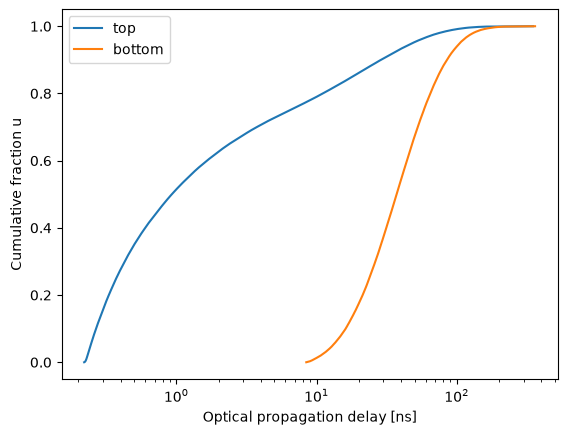

In [7]:
loaded_optical_map = load_map(optical_file)
u_values = np.linspace(0, 1, 1001)

for array_name in ["top", "bottom"]:
    delays = loaded_optical_map(u_values[:, np.newaxis], map_name=array_name)
    plt.plot(delays, u_values, label=array_name)
    print(f"{array_name:6s}: median {np.median(delays):5.1f} ns, 90 % below {np.quantile(delays, 0.9):5.1f} ns")
    print("        non-decreasing in u:", np.all(np.diff(optical_map[array_name]) >= 0))

plt.xscale("log")
plt.xlabel("Optical propagation delay [ns]")
plt.ylabel("Cumulative fraction u")
plt.legend()
plt.show()

## Effect on the S2 photon timing

What does the anode type mean for the S2 signal? We add up all four delays of the table at the top for many photons of single electrons, the same way the plugin `S2PhotonPropagation` does: emission time, excimer decay in the gas, optical propagation and PMT transit time. The plot shows the average photon time distribution of a single electron (without the PMT pulse shape):

* **Mesh**: a flat top for most of the crossing time. The triplet decay of the excimers (100 ns) rounds the rising edge and adds a tail after the end.
* **Wires**: a long low plateau and a sharp peak at the end from the light emitted close to the wire. The fast singlet decay keeps the peak narrow, the triplet decay adds a tail of about 100 ns after it.

In data, diffusion in the gas, different electron paths around the wires and variations of the gas gap across the TPC smear both shapes further.

mesh  : 10 % / 50 % / 90 % of the photons after 168 / 439 / 696 ns
wires : 10 % / 50 % / 90 % of the photons after 212 / 567 / 716 ns


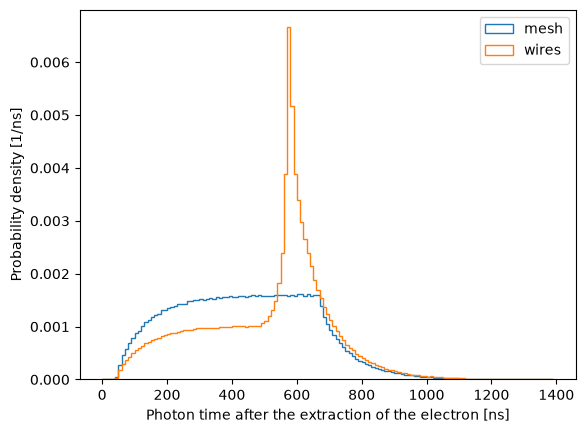

In [8]:
def detector_value(key):
    return strax.URLConfig.evaluate_dry(f"detector://{key}")


number_of_photons = 1_000_000
rng = np.random.default_rng(1)

is_singlet = rng.random(number_of_photons) < detector_value("singlet_fraction_gas")
excimer_lifetime = np.where(is_singlet, detector_value("singlet_lifetime_gas"), detector_value("triplet_lifetime_gas"))
excimer_delay = rng.exponential(excimer_lifetime)

is_top_photon = rng.random(number_of_photons) < detector_value("s2_mean_area_fraction_top")
u_optical = rng.random(number_of_photons)[:, np.newaxis]
optical_delay = np.where(
    is_top_photon,
    loaded_optical_map(u_optical, map_name="top"),
    loaded_optical_map(u_optical, map_name="bottom"),
)
transit_time = rng.normal(
    detector_value("pmt_transit_time_mean"), detector_value("pmt_transit_time_spread") / 2.355, number_of_photons
)

u_luminescence = rng.random(number_of_photons)
for label, timing_map in [("mesh", luminescence_map), ("wires", wire_luminescence_map)]:
    emission_time = np.interp(u_luminescence, u_grid, timing_map["map"])
    photon_time = emission_time + excimer_delay + optical_delay + transit_time
    plt.hist(photon_time, bins=np.arange(0, 1400, 10), histtype="step", density=True, label=label)
    print(f"{label:6s}: 10 % / 50 % / 90 % of the photons after {np.quantile(photon_time, 0.1):.0f} / "
          f"{np.quantile(photon_time, 0.5):.0f} / {np.quantile(photon_time, 0.9):.0f} ns")

plt.xlabel("Photon time after the extraction of the electron [ns]")
plt.ylabel("Probability density [1/ns]")
plt.legend()
plt.show()

### Summary

| Map | Model | Main simplifications |
|---|---|---|
| `s2_luminescence_timing_dummy.json` | light emitted along the path of the electron, field profile of a mesh (uniform) or a wire grid | straight path, no diffusion in the gas, no variation of the gas gap with $(x, y)$ |
| `s2_optical_propagation_dummy.json` | optical toy Monte Carlo | no electrodes, simplified PTFE and PMT optics, no dependence on the $(x, y)$ position of the light |

Rerun this notebook when the gas gap, the extraction field, the gas properties or the optical parameters in `detector.yaml` change.